# In this project we are going to analyze the Telcom customer data to analyze the behaviour and churn.

## About Dataset

##### Telcom Customer Churn
* Each row represents a customer, each column contains customer’s attributes described on the column Metadata.

* The raw data contains 7043 rows (customers) and 21 columns (features).

* The “Churn” column is our target.

dataset link :- [Dataset Link](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data)

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [70]:
data = pd.read_csv('Telco_Customer_Churn.csv')

In [71]:
data


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [72]:
data.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [73]:
data.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
791,3442-ZHHCC,Male,0,No,No,68,Yes,Yes,DSL,Yes,...,Yes,No,No,Yes,One year,Yes,Credit card (automatic),76.90,5023,No
6204,3058-WQDRE,Male,0,No,No,13,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),25.15,331.85,No
4214,4228-ZGYUW,Male,0,No,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,Yes,Month-to-month,Yes,Electronic check,90.05,368.1,Yes
5263,9591-YVTEB,Male,1,No,No,55,No,No phone service,DSL,Yes,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,44.85,2479.05,No
6088,3063-QFSZL,Female,0,No,No,1,Yes,No,DSL,No,...,No,No,No,Yes,Month-to-month,Yes,Electronic check,55.40,55.4,Yes
5551,8457-XIGKN,Male,0,No,No,20,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),19.60,356.15,No
438,5886-VLQVU,Male,0,Yes,No,35,Yes,Yes,Fiber optic,No,...,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.85,3161.2,No
2956,5649-RXQTV,Male,0,No,No,51,Yes,No,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.00,5038.15,No
5740,8882-TLVRW,Male,0,Yes,Yes,69,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,Two year,No,Mailed check,39.10,2779.5,No
6393,3466-RITXD,Male,0,No,No,26,Yes,Yes,Fiber optic,Yes,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),92.40,2349.8,No


## 1. Data exploration

1. How many rows and columns are there, and what is the data type of each column?

In [74]:
data.shape


(7043, 21)

In [75]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


rows = 7043, columns = 21

data types :
* float64(1) = 1 column
* int64(2) = 2 columns
* object(18) = 18 columns

Information about all columns.
 * 0   customerID         -> Customer ID
 * 1   gender             -> Whether the customer is a male or a female
 * 2   SeniorCitizen      -> Whether the customer is a senior citizen or not (1, 0)
 * 3   Partner            -> Whether the customer has a partner or not (Yes, No)
 * 4   Dependents         -> Whether the customer has dependents or not (Yes, No)
 * 5   tenure             -> Number of months the customer has stayed with the company
 * 6   PhoneService       -> Whether the customer has a phone service or not (Yes, No)
 * 7   MultipleLines      -> Whether the customer has multiple lines or not (Yes, No, No phone service)
 * 8   InternetService    -> Customer’s internet service provider (DSL, Fiber optic, No)
 * 9   OnlineSecurity     -> Whether the customer has online security or not (Yes, No, No internet service)
 * 10  OnlineBackup       -> Whether the customer has online backup or not (Yes, No, No internet service)
 * 11  DeviceProtection   -> Whether the customer has device protection or not (Yes, No, No internet service)
 * 12  TechSupport        -> Whether the customer has tech support or not (Yes, No, No internet service)
 * 13  StreamingTV        -> Whether the customer has streaming TV or not (Yes, No, No internet service)
 * 14  StreamingMovies    -> Whether the customer has streaming movies or not (Yes, No, No internet service)
 * 15  Contract           -> The contract term of the customer (Month-to-month, One year, Two year)
 * 16  PaperlessBilling   -> Whether the customer has paperless billing or not (Yes, No)
 * 17  PaymentMethod      -> The customer’s payment method (Electronic check, Mailed check, Bank transfer (automatic), Credit card
 * 18  MonthlyCharges     -> The amount charged to the customer monthly
 * 19  TotalCharges       -> The total amount charged to the customer
 * 20  Churn              -> Whether the customer churned or not (Yes or No)

2. Are any columns stored as the wrong type? (TotalCharges is text but should be numeric, and SeniorCitizen is 0/1 but is really a category.)

yes,there are two columns that have wrong data type.
* TotalCharges is text but this should be numerical values.
* in SeniorCitizen column data are '0' and '1' is considered as category but every other binary columns (Partner, Dependents, Churn) have categorical data yes/no. so converting SeniorCitizen values to yes/no data.

In [76]:
data['TotalCharges'].dtype

dtype('O')

In [77]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# errors="coerce", any invalid value is converted into NaN instead of crashing your code with an error.

In [78]:
data['TotalCharges'].dtype

dtype('float64')

In [79]:
data['TotalCharges'].sample(5)

5977    1125.60
6469     705.45
1577    1704.95
1933     415.90
560     6033.30
Name: TotalCharges, dtype: float64

In [80]:
data['SeniorCitizen'].dtype

dtype('int64')

In [81]:
# Fix SeniorCitizen: 0/1 -> No/Yes
data["SeniorCitizen"] = data["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [82]:
data['SeniorCitizen'].dtype

dtype('O')

3. Are there missing values or duplicate ?

In [83]:
data.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [84]:
data.duplicated().sum()

np.int64(0)

No, their no any duplicates.

but 11 missing values int he TotalCharge columns.

In [85]:
data['TotalCharges'] = data['TotalCharges'].fillna(0)

In [86]:
data['TotalCharges'].isna().sum()

np.int64(0)

4. What do the summary statistics (mean, median, min, max, std) show for tenure, MonthlyCharges and TotalCharges?

In [87]:
data.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


this is the statical summary of the customers.

5. Is the data imbalanced? What percentage of customers churned vs stayed?


In [88]:
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

yes, data is imbalance. Large amount of data is in No churn category.

In [89]:
churn_percentages = data["Churn"].value_counts(normalize=True) * 100
print("\nCustomer Percentages (%):")
print(churn_percentages)


Customer Percentages (%):
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


customers stayed = 73.463%  and customer churn = 26.536%

6. Are there inconsistent entries, such as "No phone service" or "No internet service" in columns that otherwise hold Yes/No?

In [90]:
# List the columns you want to check
all_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "tenure",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling",
    "PaymentMethod",
    "Churn",
]

column = []

for col in all_columns:
    print(f"--- Value counts for: {col} ---")
    print(data[col].value_counts())

    # Check if there are 3 categories/values
    if len(data[col].value_counts()) == 3:
        column.append(col)

    print("\n")  # Just adds a blank line for readability

# Optional: see which columns met your condition
print("Columns with 3 or more unique values:", column)

--- Value counts for: gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64


--- Value counts for: SeniorCitizen ---
SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64


--- Value counts for: Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64


--- Value counts for: Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64


--- Value counts for: tenure ---
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64


--- Value counts for: PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64


--- Value counts for: MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


--- Value counts for: InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


--- V

In [91]:
column

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies']

Yes, there are the columns that hold inconsistent entries, such as "No phone service" or "No internet service" in columns that otherwise hold Yes/No?

#### 2. Cleaning and transformation
1. Which customers have missing TotalCharges, and why? (Check whether they all have tenure = 0.) Should you drop them or fill them, and what is your justification?

In [92]:
data['TotalCharges'].isna().sum()

np.int64(0)

In [93]:
(data['TotalCharges']==0).sum()

np.int64(11)

In [94]:
(data['tenure']==0).sum()

np.int64(11)

11 coustomers have total charge = 0 beacuse those customers have tenure = 0.

(i.e tenure means Number of months the customer has stayed with the company. So Tenure = 0 means they are the new customers and they not charged yet.)

2. Do tenure, MonthlyCharges and TotalCharges have outliers, using box plots and the IQR rule? Are they real values or errors, and should you keep, cap or remove them?

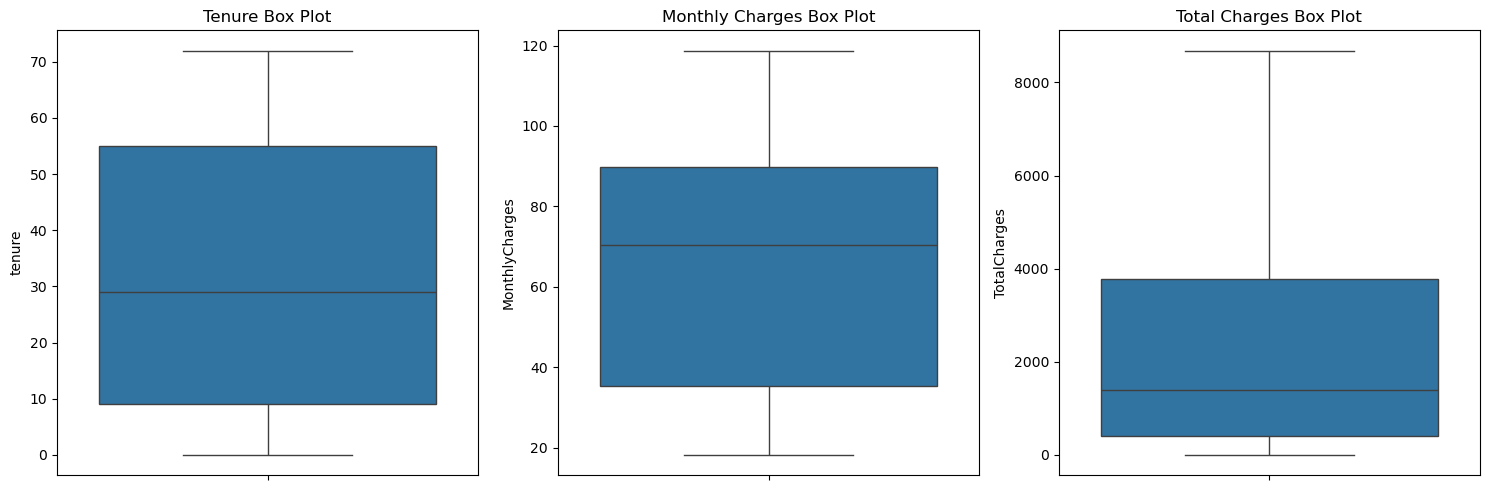

In [95]:
# Set up the plotting grid
plt.figure(figsize=(15, 5))

# 1. Tenure box plot
plt.subplot(1, 3, 1)
sns.boxplot(y=data["tenure"])
plt.title("Tenure Box Plot")

# 2. Monthly Charges box plot
plt.subplot(1, 3, 2)
sns.boxplot(y=data["MonthlyCharges"])
plt.title("Monthly Charges Box Plot")

# 3. Total Charges box plot
plt.subplot(1, 3, 3)
sns.boxplot(y=data["TotalCharges"])
plt.title("Total Charges Box Plot")

plt.tight_layout()
plt.show()

Based on the above box plots and below IQR rule, there are no outliers in tenure, MonthlyCharges, or TotalCharges.

Since no outliers exist, we don't need to cap or remove anything. All the values fall naturally within valid business ranges and statistical boundaries.

In [96]:
# for tenure 
Q1 = data['tenure'].quantile(0.25)
Q3 = data['tenure'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find points outside the bounds
outliers = data[(data['tenure'] < lower_bound) | (data['tenure'] > upper_bound)]

print(f"Column: tenure")
print(f"  - Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
print(f"  - Number of IQR outliers found: {len(outliers)}\n")

Column: tenure
  - Lower Bound: -60.00, Upper Bound: 124.00
  - Number of IQR outliers found: 0



In [97]:
# for tenure 
Q1 = data['TotalCharges'].quantile(0.25)
Q3 = data['TotalCharges'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find points outside the bounds
outliers = data[(data['TotalCharges'] < lower_bound) | (data['TotalCharges'] > upper_bound)]

print(f"Column: TotalCharges")
print(f"  - Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
print(f"  - Number of IQR outliers found: {len(outliers)}\n")

Column: TotalCharges
  - Lower Bound: -4683.52, Upper Bound: 8868.67
  - Number of IQR outliers found: 0



In [98]:
# for tenure 
Q1 = data['MonthlyCharges'].quantile(0.25)
Q3 = data['MonthlyCharges'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find points outside the bounds
outliers = data[(data['MonthlyCharges'] < lower_bound) | (data['MonthlyCharges'] > upper_bound)]

print(f"Column: MonthlyCharges")
print(f"  - Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
print(f"  - Number of IQR outliers found: {len(outliers)}\n")

Column: MonthlyCharges
  - Lower Bound: -46.02, Upper Bound: 171.38
  - Number of IQR outliers found: 0



3. Which categorical columns need encoding, and which technique fits each? (Binary mapping, one-hot encoding, or ordinal encoding for Contract.)

all columns except customerId need encoding. 
* those columns whose vales are yes/no fits Binary mapping.
* those columns whose values are in natureal order shortest to longest (Month-to-month < One year < Two year) like 'Contract' columns fits Ordinal encoding.
* those columns with different labels that have no natural order (e.g., InternetService, PaymentMethod). fits one-hot encoding.

In [99]:
data_encoded = data.drop(columns="customerID").copy()

# Merge "No internet service" / "No phone service" into "No"
cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
data_encoded[cols] = data_encoded[cols].apply(
    lambda c: c.replace({"No internet service": "No", "No phone service": "No"})
)



In [100]:
# Binary mapping: Yes/No -> 1/0

binary_cols = ["SeniorCitizen","Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"] + cols

data_encoded[binary_cols] = data_encoded[binary_cols].apply(
    lambda c: c.map({"Yes": 1, "No": 0})
).astype(int)

# Gender
data_encoded["gender"] = data_encoded["gender"].map({"Female": 0, "Male": 1})


In [101]:
# Ordinal encoding for Contract
data_encoded["Contract"] = data_encoded["Contract"].map(
    {"Month-to-month": 0, "One year": 1, "Two year": 2}
)

In [102]:
# One-hot encoding (drop_first avoids redundant columns)
data_encoded = pd.get_dummies(
    data_encoded, columns=["InternetService", "PaymentMethod"],
    drop_first=True, dtype=int
)

In [103]:
print(data_encoded.shape)
print(data_encoded.dtypes.value_counts())

(7043, 23)
int64      21
float64     2
Name: count, dtype: int64


In [104]:
data_encoded.sample(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
702,1,0,0,0,29,1,1,0,0,0,...,0,1,84.90,2516.20,0,1,0,0,1,0
3079,0,0,0,0,4,1,0,0,1,0,...,0,1,68.65,261.25,1,0,0,0,0,0
5962,1,0,1,0,16,1,0,1,1,0,...,0,0,80.75,1321.30,0,1,0,0,0,0
4376,0,0,0,0,45,1,0,1,1,0,...,1,1,100.30,4483.95,0,1,0,0,1,0
5199,0,0,0,0,51,1,1,0,1,1,...,1,1,111.50,5703.25,0,1,0,0,1,0
2886,0,0,0,0,60,1,0,1,0,1,...,0,1,104.95,6236.75,0,1,0,0,0,0
4356,0,0,0,0,3,1,0,0,0,0,...,0,0,18.80,56.00,0,0,1,0,0,1
1118,0,0,1,1,48,1,1,1,1,0,...,0,1,105.25,4997.50,0,1,0,1,0,0
6964,0,0,1,0,49,0,0,0,1,0,...,1,1,56.30,2780.60,0,0,0,1,0,0
6798,0,0,0,0,13,1,0,0,0,0,...,0,1,70.15,886.70,0,1,0,0,0,1


4. Which new features can you derive?
    * Tenure groups (0-12, 13-24, 25-48, 49-72 months)
    * Number of add-on services per customer
    * Average monthly spend (TotalCharges / tenure)
    * Whether a customer has any protection or support service

In [105]:
# 1. Tenure groups
data_encoded["tenure_group"] = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)

In [106]:
data_encoded

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group
0,0,0,1,0,1,0,0,0,1,0,...,1,29.85,29.85,0,0,0,0,1,0,0-12
1,1,0,0,0,34,1,0,1,0,1,...,0,56.95,1889.50,0,0,0,0,0,1,25-48
2,1,0,0,0,2,1,0,1,1,0,...,1,53.85,108.15,1,0,0,0,0,1,0-12
3,1,0,0,0,45,0,0,1,0,1,...,0,42.30,1840.75,0,0,0,0,0,0,25-48
4,0,0,0,0,2,1,0,0,0,0,...,1,70.70,151.65,1,1,0,0,1,0,0-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,1,0,1,...,1,84.80,1990.50,0,0,0,0,0,1,13-24
7039,0,0,1,1,72,1,1,0,1,1,...,1,103.20,7362.90,0,1,0,1,0,0,49-72
7040,0,0,1,1,11,0,0,1,0,0,...,1,29.60,346.45,0,0,0,0,1,0,0-12
7041,1,1,1,0,4,1,1,0,0,0,...,1,74.40,306.60,1,1,0,0,0,1,0-12


In [107]:
# 2. Number of add-on services per customer (0 to 6): the columns are 0/1, so just add them up
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
data_encoded["num_addons"] = data_encoded[addon_cols].sum(axis=1)

In [108]:
data_encoded

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group,num_addons
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,1,0,0-12,1
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,0,0,1,25-48,2
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,1,0-12,2
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,0,0,0,25-48,3
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,1,0,0-12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,1,0,1,...,84.80,1990.50,0,0,0,0,0,1,13-24,5
7039,0,0,1,1,72,1,1,0,1,1,...,103.20,7362.90,0,1,0,1,0,0,49-72,4
7040,0,0,1,1,11,0,0,1,0,0,...,29.60,346.45,0,0,0,0,1,0,0-12,1
7041,1,1,1,0,4,1,1,0,0,0,...,74.40,306.60,1,1,0,0,0,1,0-12,0


In [109]:
# 3. Average monthly spend (tenure 0 falls back to MonthlyCharges)
data_encoded["avg_monthly_spend"] = np.where(
    data_encoded["tenure"] > 0,
    data_encoded["TotalCharges"] / data_encoded["tenure"].replace(0, np.nan),
    data_encoded["MonthlyCharges"],
).round(3)

In [110]:
data_encoded

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group,num_addons,avg_monthly_spend
0,0,0,1,0,1,0,0,0,1,0,...,29.85,0,0,0,0,1,0,0-12,1,29.850
1,1,0,0,0,34,1,0,1,0,1,...,1889.50,0,0,0,0,0,1,25-48,2,55.574
2,1,0,0,0,2,1,0,1,1,0,...,108.15,1,0,0,0,0,1,0-12,2,54.075
3,1,0,0,0,45,0,0,1,0,1,...,1840.75,0,0,0,0,0,0,25-48,3,40.906
4,0,0,0,0,2,1,0,0,0,0,...,151.65,1,1,0,0,1,0,0-12,0,75.825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,1,0,1,...,1990.50,0,0,0,0,0,1,13-24,5,82.938
7039,0,0,1,1,72,1,1,0,1,1,...,7362.90,0,1,0,1,0,0,49-72,4,102.262
7040,0,0,1,1,11,0,0,1,0,0,...,346.45,0,0,0,0,1,0,0-12,1,31.495
7041,1,1,1,0,4,1,1,0,0,0,...,306.60,1,1,0,0,0,1,0-12,0,76.650


In [111]:
# 4. Has any protection or support service (1 = yes, 0 = no)
protect_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
data_encoded["has_protection_support"] = (data_encoded[protect_cols].sum(axis=1) > 0).astype(int)

In [112]:
data_encoded

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Churn,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group,num_addons,avg_monthly_spend,has_protection_support
0,0,0,1,0,1,0,0,0,1,0,...,0,0,0,0,1,0,0-12,1,29.850,1
1,1,0,0,0,34,1,0,1,0,1,...,0,0,0,0,0,1,25-48,2,55.574,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,0,0,1,0-12,2,54.075,1
3,1,0,0,0,45,0,0,1,0,1,...,0,0,0,0,0,0,25-48,3,40.906,1
4,0,0,0,0,2,1,0,0,0,0,...,1,1,0,0,1,0,0-12,0,75.825,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,1,0,1,...,0,0,0,0,0,1,13-24,5,82.938,1
7039,0,0,1,1,72,1,1,0,1,1,...,0,1,0,1,0,0,49-72,4,102.262,1
7040,0,0,1,1,11,0,0,1,0,0,...,0,0,0,0,1,0,0-12,1,31.495,1
7041,1,1,1,0,4,1,1,0,0,0,...,1,1,0,0,0,1,0-12,0,76.650,0


#### 3. Churn overview and retention
1. What is the overall churn rate and retention rate?

In [113]:
# Works on `data` (Churn = "Yes"/"No")
churn_counts = data["Churn"].value_counts()
churn_pct = data["Churn"].value_counts(normalize=True) * 100

print(churn_counts)
print("\n")
print(churn_pct.round(2))
print("\n")
churn_rate = churn_pct["Yes"]
retention_rate = churn_pct["No"]
print(f"Churn rate: {churn_rate:.2f}%  |  Retention rate: {retention_rate:.2f}%")


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Churn rate: 26.54%  |  Retention rate: 73.46%


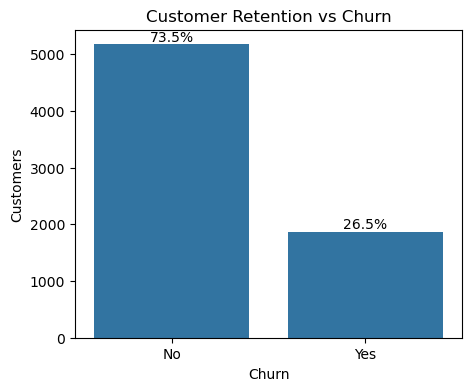

In [114]:
# Chart
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=data, x="Churn", order=["No", "Yes"], ax=ax)
for p, pct in zip(ax.patches, [retention_rate, churn_rate]):
    ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Customer Retention vs Churn")
ax.set_ylabel("Customers")
plt.show()

From figure we can see that retention rate = 73.5% and churn rate = 26.5%.

2. How does churn vary with tenure? Do customers leave mostly in the first few months?

tenure_bucket
0-3      56.2
4-6      44.6
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn_flag, dtype: float64


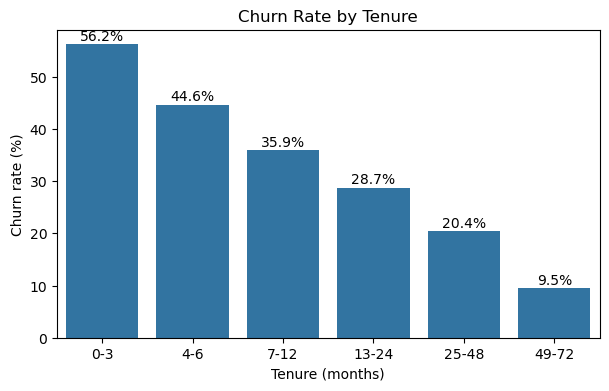

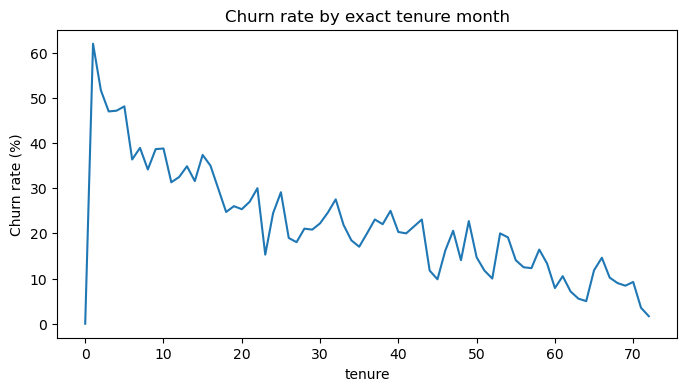

In [115]:
# Churn rate by tenure bucket (works on `data` with Churn = "Yes"/"No")
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
bins = [-1, 3, 6, 12, 24, 48, 72]
labels = ["0-3", "4-6", "7-12", "13-24", "25-48", "49-72"]
data["tenure_bucket"] = pd.cut(data["tenure"], bins=bins, labels=labels)

rate = data.groupby("tenure_bucket", observed=True)["churn_flag"].mean() * 100
print(rate.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=rate.index, y=rate.values, ax=ax)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn Rate by Tenure")
plt.show()

# month-by-month view
by_month = data.groupby("tenure")["churn_flag"].mean() * 100
by_month.plot(figsize=(8, 4), title="Churn rate by exact tenure month")
plt.ylabel("Churn rate (%)")
plt.show()

3. What does the retention curve look like by tenure bucket? (This is your "trends over time" analysis, since there is no date column.)

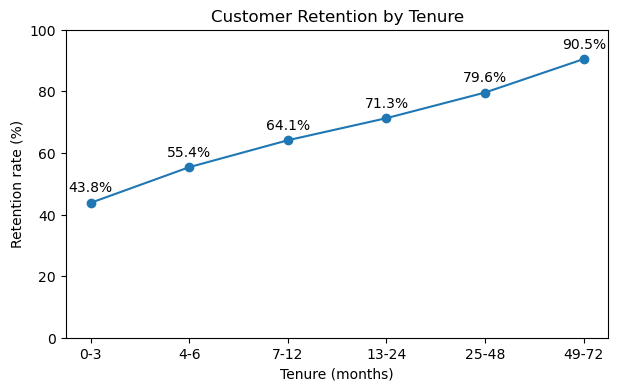

In [116]:
# 1. Retention by tenure bucket
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
bins = [-1, 3, 6, 12, 24, 48, 72]
labels = ["0-3", "4-6", "7-12", "13-24", "25-48", "49-72"]
data["tenure_bucket"] = pd.cut(data["tenure"], bins=bins, labels=labels)

retention = (1 - data.groupby("tenure_bucket", observed=True)["churn_flag"].mean()) * 100

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(retention.index.astype(str), retention.values, marker="o")
for x, y in zip(retention.index.astype(str), retention.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylim(0, 100)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Retention rate (%)")
ax.set_title("Customer Retention by Tenure")
plt.show()



4. Do churned customers have a different average tenure than retained ones?


       count  mean  median   std
Churn                           
No      5174  37.6    38.0  24.1
Yes     1869  18.0    10.0  19.5


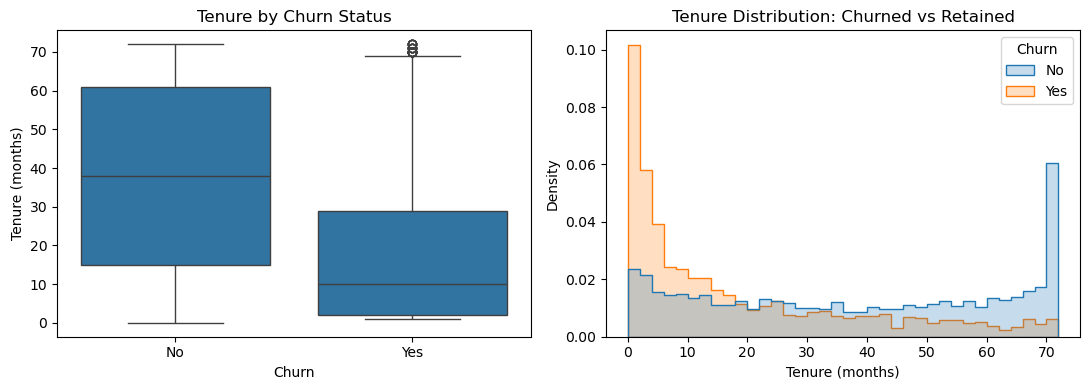

In [117]:
# Summary stats by churn group
print(data.groupby("Churn")["tenure"].agg(["count", "mean", "median", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Box plot: compare spread and medians
sns.boxplot(data=data, x="Churn", y="tenure", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
axes[0].set_ylabel("Tenure (months)")

# Histogram: compare shapes
sns.histplot(data=data, x="tenure", hue="Churn", bins=36, element="step",
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Tenure Distribution: Churned vs Retained")
axes[1].set_xlabel("Tenure (months)")

plt.tight_layout()
plt.show()

#### 4. Churn drivers
1. How does churn differ by Contract type (month-to-month, one year, two year)?

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: churn_flag, dtype: float64


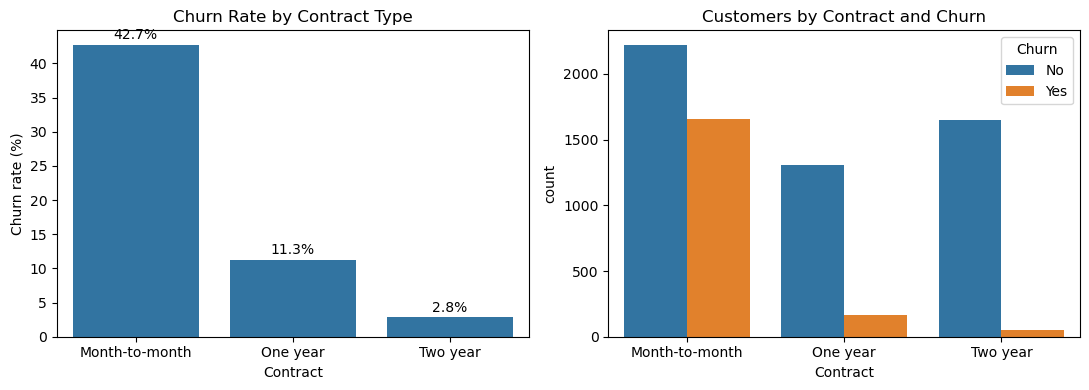

In [118]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
order = ["Month-to-month", "One year", "Two year"]

# Churn rate by contract
rate = data.groupby("Contract")["churn_flag"].mean().reindex(order) * 100
print(rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Churn rate (percentage)
sns.barplot(x=rate.index, y=rate.values, ax=axes[0])
for i, v in enumerate(rate.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_title("Churn Rate by Contract Type")

# 2. Customer counts by churn status
sns.countplot(data=data, x="Contract", hue="Churn", order=order, ax=axes[1])
axes[1].set_title("Customers by Contract and Churn")

plt.tight_layout()
plt.show()


2. Do churned customers pay more per month than retained ones? How do the MonthlyCharges distributions compare?

        count  mean   std   min   25%   50%   75%    max
Churn                                                   
No     5174.0  61.3  31.1  18.2  25.1  64.4  88.4  118.8
Yes    1869.0  74.4  24.7  18.8  56.2  79.6  94.2  118.4


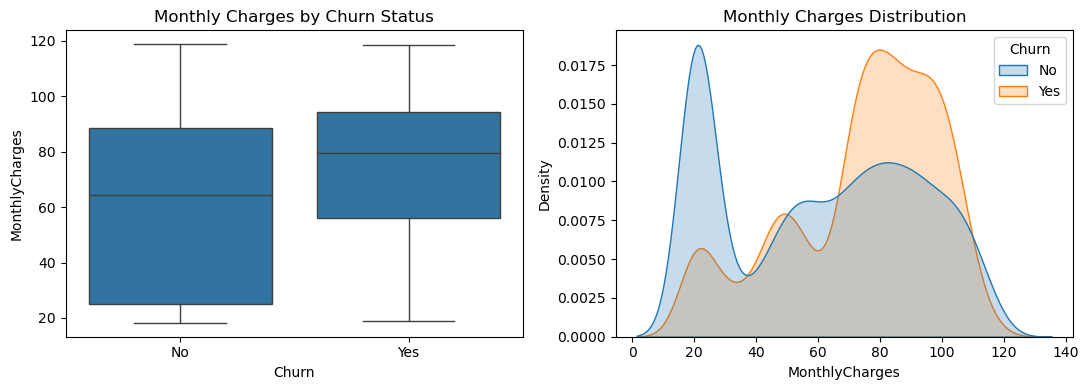

MonthlyCharges
<=30      9.8
30-50    30.8
50-70    20.8
70-90    37.8
90+      32.8
Name: churn_flag, dtype: float64


In [119]:
print(data.groupby("Churn")["MonthlyCharges"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Box plot
sns.boxplot(data=data, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Monthly Charges by Churn Status")

# Density plot (each group scaled to its own size)
sns.kdeplot(data=data, x="MonthlyCharges", hue="Churn", common_norm=False,
            fill=True, ax=axes[1])
axes[1].set_title("Monthly Charges Distribution")

plt.tight_layout()
plt.show()

# Churn rate by bill size
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
bill_bins = pd.cut(data["MonthlyCharges"], [0, 30, 50, 70, 90, 120],
                   labels=["<=30", "30-50", "50-70", "70-90", "90+"])
print((data.groupby(bill_bins, observed=True)["churn_flag"].mean() * 100).round(1))

3. How does churn vary by InternetService (DSL, fiber optic, none)? Why might fiber have higher churn?

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: churn_flag, dtype: float64


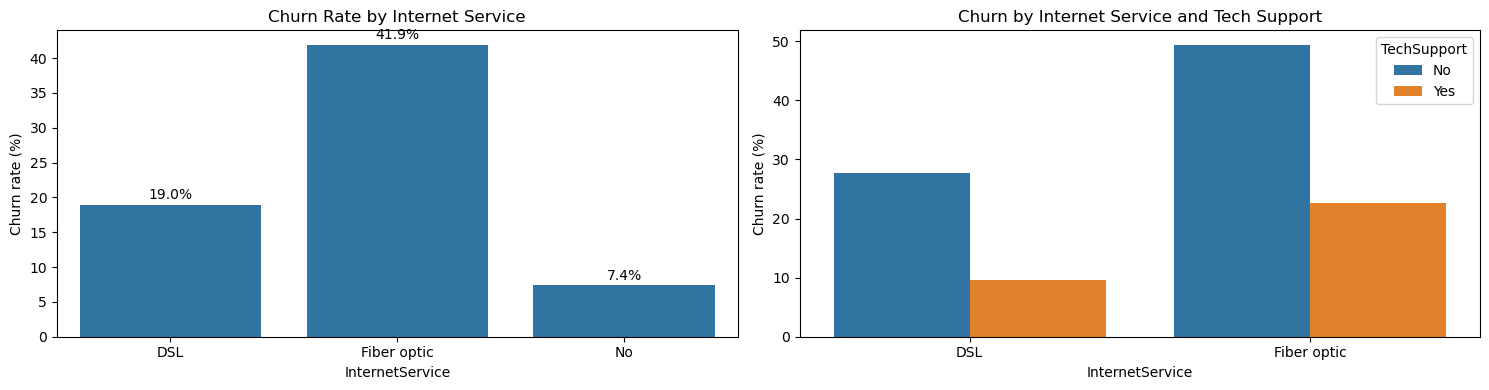

InternetService
DSL            58.1
Fiber optic    91.5
No             21.1
Name: MonthlyCharges, dtype: float64


In [120]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
order = ["DSL", "Fiber optic", "No"]

rate = data.groupby("InternetService")["churn_flag"].mean().reindex(order) * 100
print(rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# 1. Churn rate by internet service
sns.barplot(x=rate.index, y=rate.values, ax=axes[0])
for i, v in enumerate(rate.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_title("Churn Rate by Internet Service")

# 2. Effect of tech support within internet customers
sns.barplot(data=data[data["InternetService"] != "No"], x="InternetService", y="churn_flag",
            hue="TechSupport", estimator=lambda x: x.mean() * 100, errorbar=None, ax=axes[1])
axes[1].set_ylabel("Churn rate (%)")
axes[1].set_title("Churn by Internet Service and Tech Support")

plt.tight_layout()
plt.show()

# Supporting numbers
print(data.groupby("InternetService")["MonthlyCharges"].mean().round(1))

4. Do add-on services (OnlineSecurity, TechSupport, OnlineBackup, DeviceProtection) lower churn?

Churn Rate With and Without Add-on Services:
                    No   Yes
OnlineSecurity    41.8  14.6
OnlineBackup      39.9  21.5
DeviceProtection  39.1  22.5
TechSupport       41.6  15.2


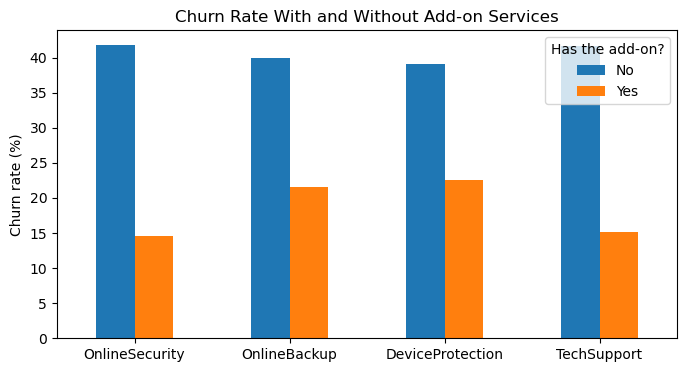

In [121]:

data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# keep only customers who have internet service
internet = data[data["InternetService"] != "No"]

# the four add-on columns we want to check
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]

# churn rate (%) for customers WITH and WITHOUT each add-on
results = {}
for col in addons:
    results[col] = internet.groupby(col)["churn_flag"].mean() * 100

table = pd.DataFrame(results).T.round(1)
print("Churn Rate With and Without Add-on Services:")
print(table)


# bar chart
table.plot(kind="bar", figsize=(8, 4))
plt.title("Churn Rate With and Without Add-on Services")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Has the add-on?")
plt.show()

from above figure we can clearly see that Churn Rate is drastically reduced With Add-on Services.

5. Do StreamingTV and StreamingMovies affect churn?

Churn Rate With and Without Streaming Services
                   No   Yes
StreamingTV      33.5  30.1
StreamingMovies  33.7  29.9


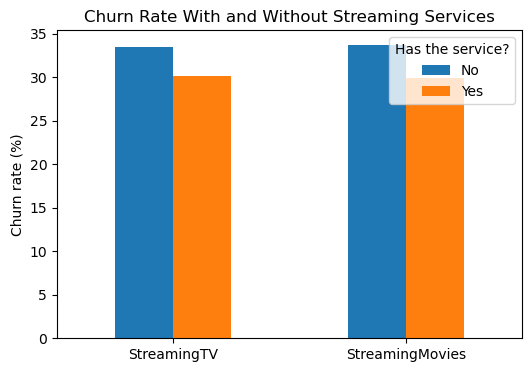

In [122]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
internet = data[data["InternetService"] != "No"]

# the two streaming columns
streaming = ["StreamingTV", "StreamingMovies"]

# Step 4: churn rate (%) for customers WITH and WITHOUT streaming service
results = {}
for col in streaming:
    results[col] = internet.groupby(col)["churn_flag"].mean() * 100

table = pd.DataFrame(results).T.round(1)
print("Churn Rate With and Without Streaming Services")
print(table)

# Step 5: bar chart
table.plot(kind="bar", figsize=(6, 4))
plt.title("Churn Rate With and Without Streaming Services")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Has the service?")
plt.show()


from above figure we can see that, churn rate change about 3% With and Without Streaming Services. 

if we provide streaming services then churn rate is reduced by 3% and if not then churn rate increase about 3%.

6. Does PaymentMethod matter? (Electronic check is often linked with higher churn.)

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: churn_flag, dtype: float64


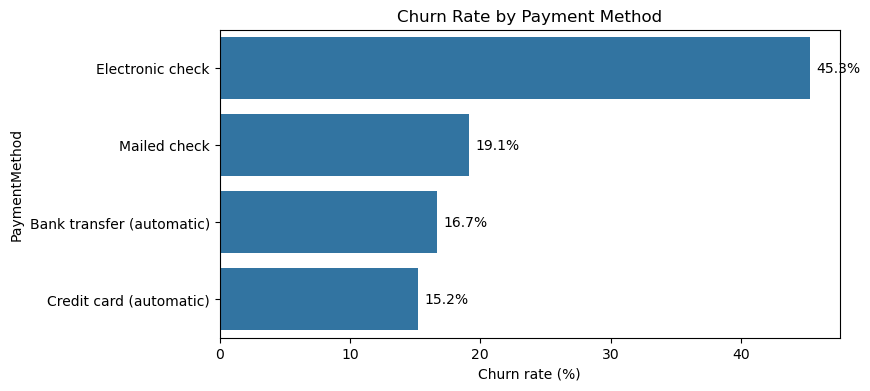

In [123]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# churn rate (%) for each payment method
rate = data.groupby("PaymentMethod")["churn_flag"].mean() * 100
rate = rate.sort_values(ascending=False)
print(rate.round(1))

# bar chart
plt.figure(figsize=(8, 4))
sns.barplot(x=rate.values, y=rate.index)
for i, v in enumerate(rate.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.xlabel("Churn rate (%)")
plt.title("Churn Rate by Payment Method")
plt.show()

yes, payment method matters alot. we can see Electronic Check payment method have the highest churn rate = 45.3%.

7. Does PaperlessBilling relate to churn?

PaperlessBilling
No     16.3
Yes    33.6
Name: churn_flag, dtype: float64


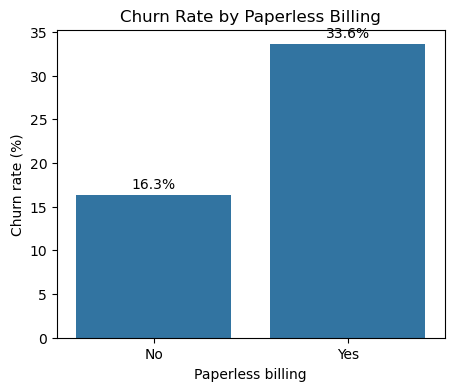

In [124]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# churn rate (%) for paperless vs paper billing
rate = data.groupby("PaperlessBilling")["churn_flag"].mean() * 100
print(rate.round(1))

# bar chart
plt.figure(figsize=(5, 4))
sns.barplot(x=rate.index, y=rate.values)
for i, v in enumerate(rate.values):
    plt.text(i, v + 0.8, f"{v:.1f}%", ha="center")
plt.xlabel("Paperless billing")
plt.ylabel("Churn rate (%)")
plt.title("Churn Rate by Paperless Billing")
plt.show()

Yes, paperless billing is highly related to churn. if we provide paper billing then churn rate = 16.3% but if we provide paperless billing then churn rate doubled about 33.6%.

8. Does churn differ by gender, SeniorCitizen, Partner or Dependents?

gender
gender
Female    26.9
Male      26.2
Name: churn_flag, dtype: float64

SeniorCitizen
SeniorCitizen
No     23.6
Yes    41.7
Name: churn_flag, dtype: float64

Partner
Partner
No     33.0
Yes    19.7
Name: churn_flag, dtype: float64

Dependents
Dependents
No     31.3
Yes    15.5
Name: churn_flag, dtype: float64



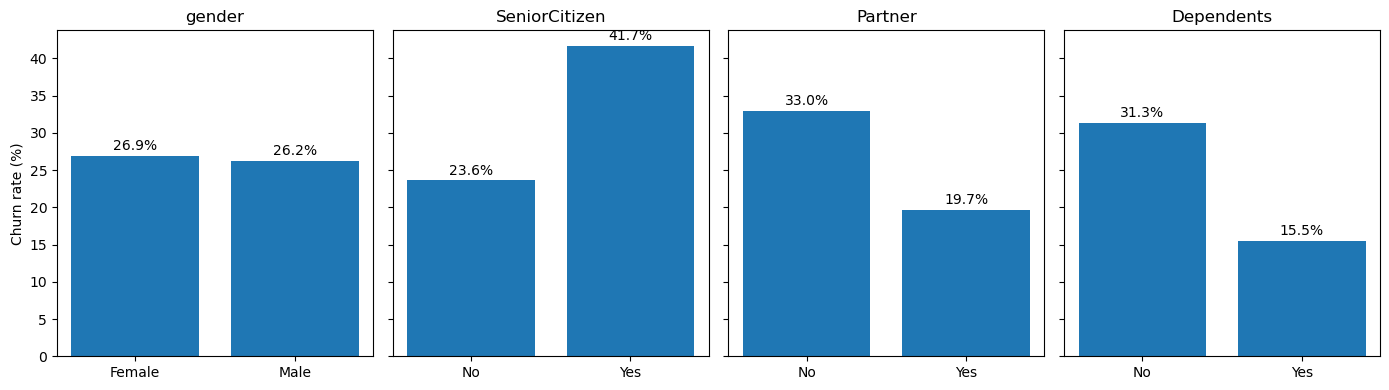

In [125]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# columns to check
cols = ["gender", "SeniorCitizen", "Partner", "Dependents"]

# churn rate (%) for each group
for col in cols:
    print(col)
    print((data.groupby(col)["churn_flag"].mean() * 100).round(1))
    print()

# four small bar charts side by side
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, cols):
    rate = data.groupby(col)["churn_flag"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
    ax.set_title(col)
axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

- Gender do not make any difference in churn rate.
- if customers are seniorCitizens then churn rate = 41.7% which is very high.
- if customers have partner then churn rate is low (churn rate = 19.7) and if customers do not have partner then churn rate is high ( churn rate = 33% )
- if customer is dependent then churn rate is low (churn rate = 15.5%) and if customer is independent then churn rate is high (churn rate = 31.3%)

9. Does having PhoneService or MultipleLines change churn?

PhoneService
PhoneService
No     24.9
Yes    26.7
Name: churn_flag, dtype: float64

MultipleLines
MultipleLines
No                  25.0
No phone service    24.9
Yes                 28.6
Name: churn_flag, dtype: float64



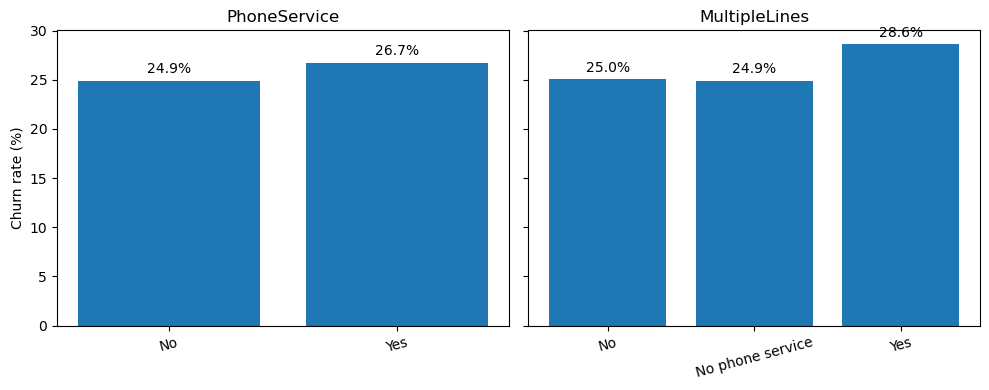

In [126]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# churn rate (%) for PhoneService and MultipleLines
for col in ["PhoneService", "MultipleLines"]:
    print(col)
    print((data.groupby(col)["churn_flag"].mean() * 100).round(1))
    print()

# two bar charts side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col in zip(axes, ["PhoneService", "MultipleLines"]):
    rate = data.groupby(col)["churn_flag"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=15)
    
axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

PhoneService and MultipleLines shows very little effect on the churn rate.

#### 5. Correlations
1. Which numeric features are most correlated with churn (after encoding Churn as 0/1)?

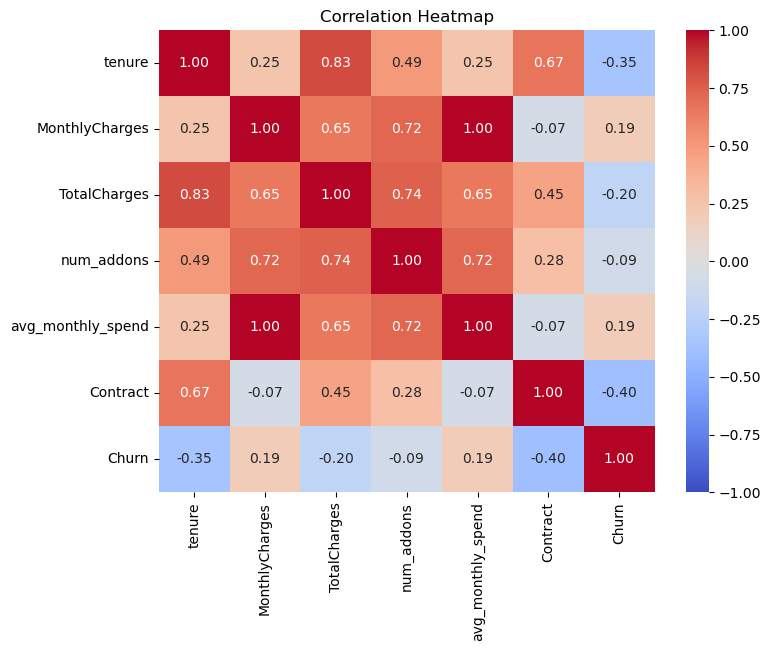

In [127]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_addons",
                "avg_monthly_spend", "Contract", "Churn"]

corr = data_encoded[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Answer:** The heatmap shows that `Contract` (-0.40) and `tenure` (-0.35) are the numeric
features having most strongly correlated with churn. Both are negative: customers on longer
contracts and with longer tenure are far less likely to churn. `TotalCharges` (-0.20) and
`MonthlyCharges` (+0.19) show a moderate relationship, while `num_addons` (-0.09) is weak.
`TotalCharges` largely reflects tenure (r = 0.83), and `avg_monthly_spend` duplicates
`MonthlyCharges` (r = 1.00). No single numeric feature has a correlation above 0.4, so
churn is driven by a combination of factors.

**Are there highly correlated features?**
**Answer:** Yes, several features are highly correlated. `MonthlyCharges` and
`avg_monthly_spend` are almost perfectly correlated (1.00), since average monthly spend is
derived from the monthly bill. `tenure` and `TotalCharges` are also strongly correlated
(0.83), because total charges accumulate with the number of months a customer has stayed.
Other notable pairs are `TotalCharges` with `num_addons` (0.74), `MonthlyCharges` with
`num_addons` (0.72) and `tenure` with `Contract` (0.67).

2. What does the full correlation heatmap show?

**Answer:** The full heatmap shows that no single feature is strongly correlated with churn;
the largest values are Contract (-0.40), tenure (-0.35), Fiber optic internet (+0.31) and
Electronic check payment (+0.30). Longer contracts and tenure, having no internet service,
and add-ons such as OnlineSecurity and TechSupport go with lower churn, while fiber optic,
electronic check, paperless billing and higher monthly charges go with higher churn.
`gender`, `PhoneService` and `MultipleLines` are close to zero. Features also cluster:
billing features (MonthlyCharges, fiber optic, num_addons) move together, as do tenure-related
features (tenure, TotalCharges, Contract). Derived features such as `tenure_group` and
`avg_monthly_spend` are nearly duplicates of their source columns. Correlation shows
association, not causation.

#### 6. Segmentation and loyalty
1. Which customer segment has the highest churn? (For example: month-to-month, fiber optic, electronic check, no tech support, tenure under 12 months.)

Month-to-month: 3875 customers, churn 42.7%
Fiber optic: 3096 customers, churn 41.9%
Electronic check: 2365 customers, churn 45.3%
No tech support: 3473 customers, churn 41.6%
Tenure <= 12 months: 2186 customers, churn 47.4%
High-risk segment: 589 customers, churn 72.3%


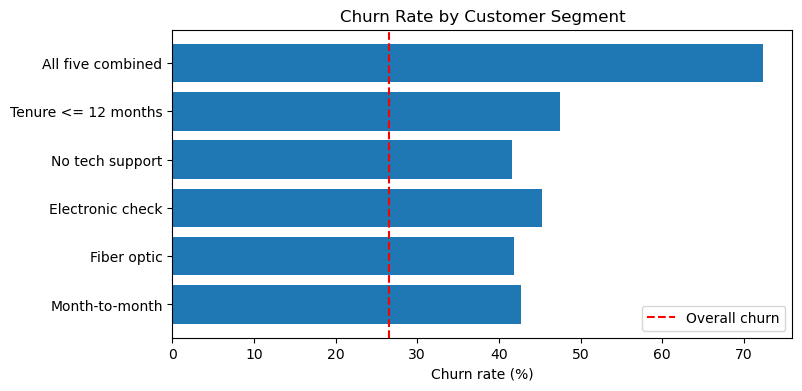

In [128]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# define each risk trait as True/False for every customer
month_to_month   = data["Contract"] == "Month-to-month"
fiber            = data["InternetService"] == "Fiber optic"
electronic_check = data["PaymentMethod"] == "Electronic check"
no_tech_support  = data["TechSupport"] == "No"        # internet customers without support
new_customer     = data["tenure"] <= 12

# churn rate of each single segment
segments = {
    "Month-to-month": month_to_month,
    "Fiber optic": fiber,
    "Electronic check": electronic_check,
    "No tech support": no_tech_support,
    "Tenure <= 12 months": new_customer,
}
for name, mask in segments.items():
    print(f"{name}: {mask.sum()} customers, churn {data.loc[mask, 'churn_flag'].mean() * 100:.1f}%")

# combine all five traits into one high-risk segment
high_risk = month_to_month & fiber & electronic_check & no_tech_support & new_customer
print(f"High-risk segment: {high_risk.sum()} customers, "
      f"churn {data.loc[high_risk, 'churn_flag'].mean() * 100:.1f}%")

# chart
names = list(segments) + ["All five combined"]
rates = [data.loc[m, "churn_flag"].mean() * 100 for m in segments.values()] + \
        [data.loc[high_risk, "churn_flag"].mean() * 100]
plt.figure(figsize=(8, 4))
plt.barh(names, rates)
plt.axvline(data["churn_flag"].mean() * 100, color="red", linestyle="--", label="Overall churn")
plt.xlabel("Churn rate (%)")
plt.title("Churn Rate by Customer Segment")
plt.legend()
plt.show()

from above data and figure we can the tenure less then 12 months have highest churn rate (i.e 47.4%)

2. Which segment is the most loyal? (For example: two-year contract, with security and support add-ons, tenure over 4 years.)

Two-year contract: 1695 customers, churn 2.8%
Tenure > 48 months: 2239 customers, churn 9.5%
Online security: 2019 customers, churn 14.6%
Tech support: 2044 customers, churn 15.2%
Automatic payment: 3066 customers, churn 16.0%
Loyal segment: 516 customers, churn 3.5%


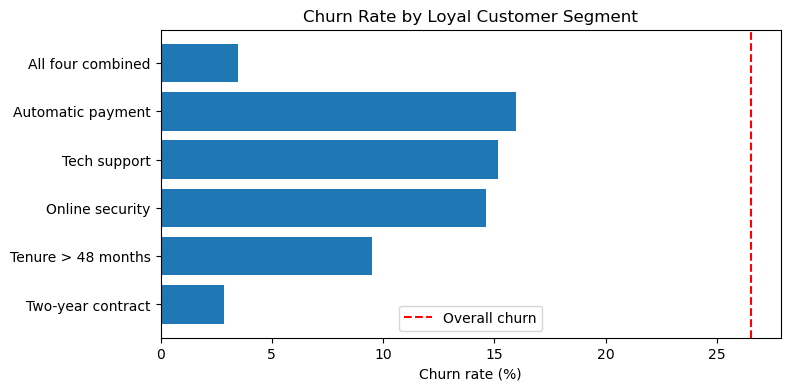

In [129]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# each loyalty trait as True/False for every customer
two_year   = data["Contract"] == "Two year"
long_stay  = data["tenure"] > 48
security   = data["OnlineSecurity"] == "Yes"
support    = data["TechSupport"] == "Yes"
auto_pay   = data["PaymentMethod"].str.contains("automatic")

# churn rate of each single segment
segments = {
    "Two-year contract": two_year,
    "Tenure > 48 months": long_stay,
    "Online security": security,
    "Tech support": support,
    "Automatic payment": auto_pay,
}
for name, mask in segments.items():
    print(f"{name}: {mask.sum()} customers, churn {data.loc[mask, 'churn_flag'].mean() * 100:.1f}%")

# combine into one loyal segment
loyal = two_year & long_stay & security & support
print(f"Loyal segment: {loyal.sum()} customers, "
      f"churn {data.loc[loyal, 'churn_flag'].mean() * 100:.1f}%")

# chart
names = list(segments) + ["All four combined"]
rates = [data.loc[m, "churn_flag"].mean() * 100 for m in segments.values()] + \
        [data.loc[loyal, "churn_flag"].mean() * 100]
plt.figure(figsize=(8, 4))
plt.barh(names, rates)
plt.axvline(data["churn_flag"].mean() * 100, color="red", linestyle="--", label="Overall churn")
plt.xlabel("Churn rate (%)")
plt.title("Churn Rate by Loyal Customer Segment")
plt.legend()
plt.show()

most loyal customers are Two-year contract customers, total customers: 1695, churn rate = 2.8%

3. How do contract type, tenure and monthly charges interact? Does a high price combined with a month-to-month contract push churn up?

Contract     Month-to-month  One year  Two year
price_band                                     
Low (<=35)             24.3       3.1       0.8
Mid (35-70)            35.3       7.8       2.1
High (>70)             52.7      17.4       4.8


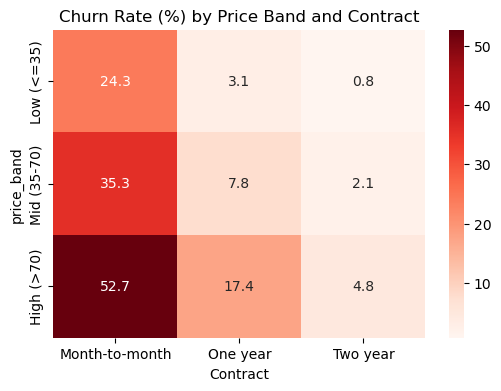

tenure_band  0-12  13-24  25-48  49-72
price_band                            
Low (<=35)   28.9   12.6   12.7   11.1
Mid (35-70)  45.5   27.0   15.8   16.4
High (>70)   69.0   49.1   41.7   28.7


In [130]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# group monthly charges into Low / Mid / High
data["price_band"] = pd.cut(data["MonthlyCharges"], bins=[0, 35, 70, 120],
                            labels=["Low (<=35)", "Mid (35-70)", "High (>70)"])

# churn rate (%) by price band and contract
table = data.pivot_table(index="price_band", columns="Contract",
                         values="churn_flag", aggfunc="mean", observed=True) * 100
table = table[["Month-to-month", "One year", "Two year"]]
print(table.round(1))

# heatmap of the table
plt.figure(figsize=(6, 4))
sns.heatmap(table, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn Rate (%) by Price Band and Contract")
plt.show()

# add tenure groups, then look at month-to-month customers only
data["tenure_band"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 48, 72],
                             labels=["0-12", "13-24", "25-48", "49-72"])
m2m = data[data["Contract"] == "Month-to-month"]
table2 = m2m.pivot_table(index="price_band", columns="tenure_band",
                         values="churn_flag", aggfunc="mean", observed=True) * 100
print(table2.round(1))

Yes. A high monthly price combined with a month-to-month contract pushes churn up
sharply, and contract type has an even larger effect than price.

4. Do senior citizens or customers living alone (no partner or dependents) churn more within each contract type?

senior_label    Non-senior  Senior
Contract                          
Month-to-month        39.6    54.6
One year              10.7    15.3
Two year               2.7     4.1

alone_label     Living alone  Not alone
Contract                               
Month-to-month          45.8       38.3
One year                10.9       11.5
Two year                 3.5        2.6


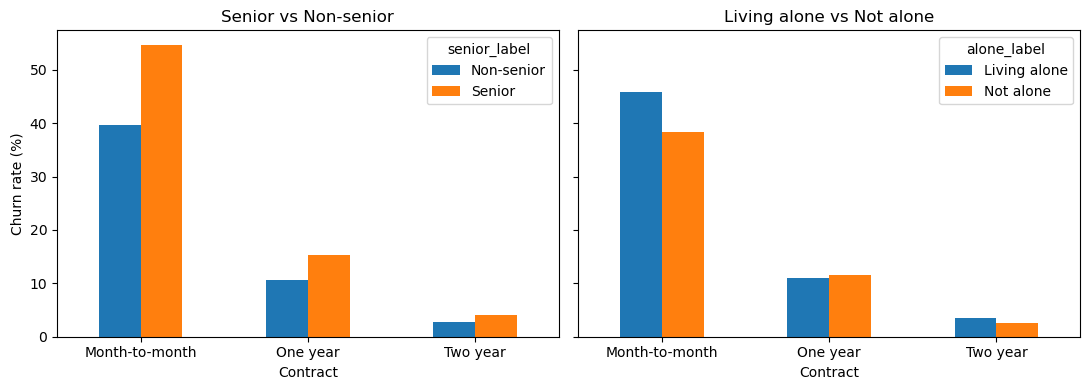

In [131]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# label the two groups
data["senior_label"] = np.where(data["SeniorCitizen"].isin([1, "Yes"]), "Senior", "Non-senior")
data["alone_label"] = np.where((data["Partner"] == "No") & (data["Dependents"] == "No"),
                               "Living alone", "Not alone")

# churn rate (%) by contract for each group
order = ["Month-to-month", "One year", "Two year"]
senior = data.pivot_table(index="Contract", columns="senior_label",
                          values="churn_flag", aggfunc="mean").loc[order] * 100
alone = data.pivot_table(index="Contract", columns="alone_label",
                         values="churn_flag", aggfunc="mean").loc[order] * 100
print(senior.round(1))
print()
print(alone.round(1))

# side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
senior.plot(kind="bar", ax=axes[0], rot=0, title="Senior vs Non-senior")
alone.plot(kind="bar", ax=axes[1], rot=0, title="Living alone vs Not alone")
axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

**Answer:** Yes, senior citizens churn more than non-seniors in every contract type
(month-to-month 54.6% vs 39.6%, one year 15.3% vs 10.7%, two year 4.1% vs 2.7%).
The gap is large on month-to-month contracts and smaller on longer contracts.

Customers living alone churn more than those who are not alone only on month-to-month
contracts: 45.8% vs 38.3%, about 7.5 percentage points higher. On one-year and two-year
contracts the churn rates are nearly equal (10.9% vs 11.5% and 3.5% vs 2.6%, less than
1 point apart).

**Conclusion:** Seniors and customers living alone are more likely to churn when they are free
to leave (month-to-month). Longer contracts largely remove the difference for customers living
alone.

5. Which segments are highest in both customer count and churn rate, so they are the best targets for retention efforts?

                                    segment  customers  churn_rate_%  lift  \
0                            Month-to-month       3875          42.7  1.61   
1                    Month-to-month + fiber       2128          54.6  2.06   
4  Month-to-month + fiber + no tech support       1796          57.5  2.17   
2               Month-to-month + first year       1994          51.4  1.94   
3         Month-to-month + electronic check       1850          53.7  2.02   
5       Month-to-month + fiber + first year        916          70.2  2.65   
6                           Senior citizens       1142          41.7  1.57   

   churned  
0     1655  
1     1162  
4     1033  
2     1024  
3      994  
5      643  
6      476  


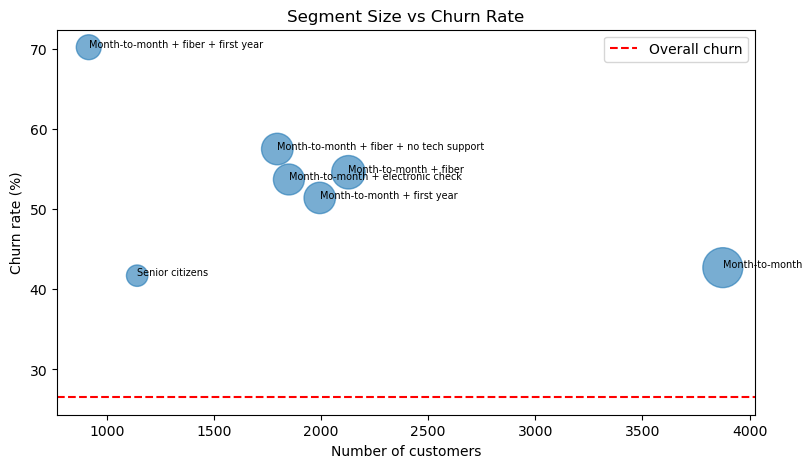

In [132]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
overall = data["churn_flag"].mean()

# define the segments as True/False for each customer
m2m = data["Contract"] == "Month-to-month"
fiber = data["InternetService"] == "Fiber optic"
segments = {
    "Month-to-month": m2m,
    "Month-to-month + fiber": m2m & fiber,
    "Month-to-month + first year": m2m & (data["tenure"] <= 12),
    "Month-to-month + electronic check": m2m & (data["PaymentMethod"] == "Electronic check"),
    "Month-to-month + fiber + no tech support": m2m & fiber & (data["TechSupport"] == "No"),
    "Month-to-month + fiber + first year": m2m & fiber & (data["tenure"] <= 12),
    "Senior citizens": data["SeniorCitizen"].isin([1, "Yes"]),
}

# build a summary table
rows = []
for name, mask in segments.items():
    n = mask.sum()
    rate = data.loc[mask, "churn_flag"].mean()
    churned = data.loc[mask, "churn_flag"].sum()
    rows.append([name, n, round(rate * 100, 1), round(rate / overall, 2), churned])
table = pd.DataFrame(rows, columns=["segment", "customers", "churn_rate_%", "lift", "churned"])
print(table.sort_values("churned", ascending=False))

# bubble chart (size = number of churned customers)
plt.figure(figsize=(9, 5))
plt.scatter(table["customers"], table["churn_rate_%"], s=table["churned"] / 2, alpha=0.6)
for _, r in table.iterrows():
    plt.annotate(r["segment"], (r["customers"], r["churn_rate_%"]), fontsize=7)
plt.axhline(overall * 100, color="red", linestyle="--", label="Overall churn")
plt.xlabel("Number of customers")
plt.ylabel("Churn rate (%)")
plt.title("Segment Size vs Churn Rate")
plt.legend()
plt.show()

**Answer:** The best retention targets are segments that are both large (many customers) and
high-risk (high churn rate). The bubble chart and table show that **month-to-month customers on
fiber optic plans** are the clearest priority.

| Segment | Customers | Churn rate | Churned |
|---|---|---|---|
| Month-to-month | 3,875 | 42.7% | 1,655 |
| Month-to-month + fiber | 2,128 | 54.6% | 1,162 |
| Month-to-month + fiber + no tech support | 1,796 | 57.5% | 1,033 |
| Month-to-month + first year | 1,994 | 51.4% | 1,024 |
| Month-to-month + electronic check | 1,850 | 53.7% | 994 |
| Month-to-month + fiber + first year | 916 | 70.2% | 643 |
| Senior citizens | 1,142 | 41.7% | 476 |

**Key findings:**
- **Month-to-month + fiber** is the best balance of size and risk: 2,128 customers churning at
  54.6%, about twice the overall rate of 26.5%, and responsible for 1,162 of the 1,869 churned
  customers.
- **Month-to-month + fiber + first year** has the highest churn rate (70.2%), but it is a smaller
  group (916 customers), so it is best for early, focused outreach.
- **Month-to-month overall** has the most churned customers (1,655) but a lower rate (42.7%), so
  it is a broad target rather than a precise one.
- **Senior citizens** are a smaller group (1,142 customers), so they matter less for total volume
  even though their churn rate (41.7%) is high.
- Every segment shown churns well above the overall average (red dashed line in the chart).

**Recommendation:** Prioritise month-to-month fiber customers, especially those in their first
year or without tech support, with offers such as contract-upgrade incentives, bundled tech
support, and early-tenure onboarding.

#### 7. Business insights
1. What are the top 3-5 drivers of churn, ranked by evidence?

In [133]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
print("Overall churn rate (%):", round(data["churn_flag"].mean() * 100, 1))

# Driver 1: Contract type
print((data.groupby("Contract")["churn_flag"].mean() * 100).round(1))

# Driver 2: Tenure (group the months first)
data["tenure_group"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 48, 72],
                              labels=["0-12", "13-24", "25-48", "49-72"])
print((data.groupby("tenure_group", observed=True)["churn_flag"].mean() * 100).round(1))

# Driver 3: Internet service type
print((data.groupby("InternetService")["churn_flag"].mean() * 100).round(1))

# Driver 4: Online security and tech support (only customers who have internet)
internet = data[data["InternetService"] != "No"]
print((internet.groupby("OnlineSecurity")["churn_flag"].mean() * 100).round(1))  
print((internet.groupby("TechSupport")["churn_flag"].mean() * 100).round(1))      

# Driver 5: Payment method
print((data.groupby("PaymentMethod")["churn_flag"].mean() * 100).round(1))
 


Overall churn rate (%): 26.5
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: churn_flag, dtype: float64
tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn_flag, dtype: float64
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: churn_flag, dtype: float64
OnlineSecurity
No     41.8
Yes    14.6
Name: churn_flag, dtype: float64
TechSupport
No     41.6
Yes    15.2
Name: churn_flag, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: churn_flag, dtype: float64


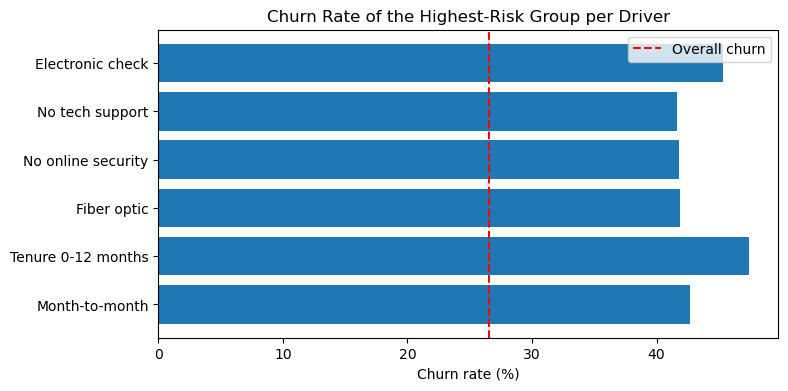

In [134]:
# One chart for all the main drivers: churn rate of the riskiest group in each
risky = {
    "Month-to-month": 42.7, "Tenure 0-12 months": 47.4, "Fiber optic": 41.9,
    "No online security": 41.8, "No tech support": 41.6, "Electronic check": 45.3,
}
plt.figure(figsize=(8, 4))
plt.barh(list(risky), list(risky.values()))
plt.axvline(data["churn_flag"].mean() * 100, color="red", linestyle="--", label="Overall churn")
plt.xlabel("Churn rate (%)")
plt.title("Churn Rate of the Highest-Risk Group per Driver")
plt.legend()
plt.show()

**Answer:** The chart shows the churn rate of the highest-risk group for each driver. All six
groups churn at roughly 41-47%, well above the overall churn rate of 26.5% (red dashed line),
so each is a meaningful risk factor.

**Churn rate of the highest-risk group (from the chart):**
- Tenure 0-12 months: 47.4%
- Electronic check payment: 45.3%
- Month-to-month contract: 42.7%
- Fiber optic internet: 41.9%
- No online security: 41.8%
- No tech support: 41.6%

**Top drivers ranked by evidence:**
| Rank | Driver | Evidence |
|---|---|---|
| 1 | Month-to-month contract | Strongest correlation with churn (-0.40) and 88.6% of all churn comes from this group. Churn is 42.7% vs 11.3% (one year) and 2.8% (two year), and the pattern holds within every price, tenure and service group. |
| 2 | Short tenure (first 12 months) | Highest churn rate of any group (47.4%) vs 9.5% for customers with 49-72 months of tenure. 55.5% of churned customers left within their first year. |
| 3 | Fiber optic internet | 41.9% churn vs 19.0% for DSL and 7.4% for no internet. 69.4% of all churn. Higher than DSL within every contract type. |
| 4 | No online security / no tech support | 41.8% / 41.6% churn vs 14.6% / 15.2% for customers who have them (internet customers only). Strongest on month-to-month contracts. |
| 5 | Electronic check payment | 45.3% churn vs 15.2-19.1% for other methods. 57.3% of all churn. |


2. What actions would reduce churn? (For example: contract upgrade offers, bundling security and tech support, early-tenure onboarding, nudging customers off electronic checks.)

**Answer:** Based on the main churn drivers, the following actions are recommended, in priority order.

| Priority | Action | Target group | Supporting evidence |
|---|---|---|---|
| 1 | Contract upgrade offers (discount or perk for a 1- or 2-year plan) | Month-to-month customers, starting with fiber (2,128 customers, 54.6% churn) | Month-to-month churn is 42.7% vs 11.3% (one year) and 2.8% (two year); these customers account for 88.6% of all churn |
| 2 | Early-tenure onboarding (check-ins at months 1, 3, 6; setup help; welcome offer) | Customers in their first 12 months (47.4% churn) | Churn is 56.2% in months 0-3 and falls to 9.5% for 49-72 months; 55.5% of churned customers left within the first year |
| 3 | Bundle or trial security and tech support | Internet customers without these services, especially fiber | Churn is 41.8% without online security vs 14.6% with it, and 41.6% without tech support vs 15.2% with it |
| 4 | Encourage a switch from electronic check to automatic payment (e.g. small bill credit) | Electronic check users (45.3% churn) | Automatic payment methods churn at 15-17%; the gap remains within month-to-month customers |
| 5 | Review the fiber optic experience (pricing, service quality, loyalty pricing, exit surveys) | Fiber customers (41.9% churn) | Fiber churns about twice as much as DSL (19.0%), across all contract types |
| 6 | Senior-friendly support (assisted setup, easier access to help) | Senior citizens (41.7% churn) | Seniors churn more than non-seniors in every contract type |

**Where to start:** Pilot the actions on the highest-risk segment, month-to-month fiber customers
in their first year (916 customers, 70.2% churn), where each retained customer has the greatest impact.

**How to measure:** Offer each action to a random half of the target group and compare churn
against the other half over a fixed period, so the effect of the action can be separated from
customers who would have stayed anyway. Compare the cost of each offer with the revenue retained.

**Notes:** These recommendations are based on associations in the data, not proven causes, so
they should be tested before being rolled out widely. Gender, phone service, multiple lines and
streaming services showed no clear relationship with churn and are not recommended targets.

3. How much revenue is at risk from churned customers' MonthlyCharges?

Total monthly revenue: 456116.6
Monthly revenue from churned customers: 139130.85
Share of revenue at risk (%): 30.5
Annual revenue (x12): 1669570.2
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64
Contract
Month-to-month    120847.0
One year           14118.0
Two year            4165.0
Name: MonthlyCharges, dtype: float64
InternetService
DSL             22529.0
Fiber optic    114300.0
No               2302.0
Name: MonthlyCharges, dtype: float64


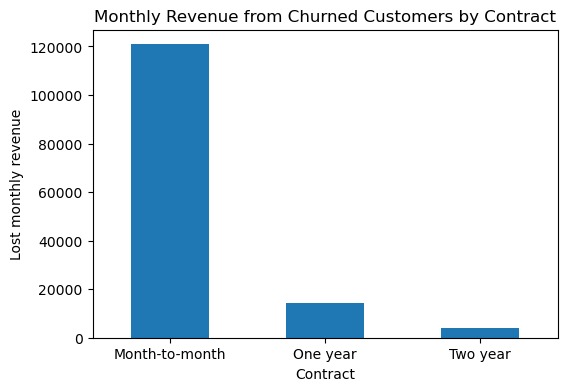

In [135]:
data["churn_flag"] = (data["Churn"] == "Yes").astype(int)

# total monthly revenue and revenue from churned customers
total_revenue = data["MonthlyCharges"].sum()
lost_revenue = data.loc[data["churn_flag"] == 1, "MonthlyCharges"].sum()

print("Total monthly revenue:", round(total_revenue, 2))
print("Monthly revenue from churned customers:", round(lost_revenue, 2))
print("Share of revenue at risk (%):", round(lost_revenue / total_revenue * 100, 1))
print("Annual revenue (x12):", round(lost_revenue * 12, 2))

# average monthly charge for churned vs retained customers
print(data.groupby("Churn")["MonthlyCharges"].mean().round(2))

# where the lost revenue comes from
lost = data[data["churn_flag"] == 1]
print((lost.groupby("Contract")["MonthlyCharges"].sum()).round(0))
print((lost.groupby("InternetService")["MonthlyCharges"].sum()).round(0))

# chart - lost monthly revenue by contract type
import matplotlib.pyplot as plt
lost.groupby("Contract")["MonthlyCharges"].sum().plot(kind="bar", figsize=(6, 4), rot=0)
plt.ylabel("Lost monthly revenue")
plt.title("Monthly Revenue from Churned Customers by Contract")
plt.show()

**Answer:** Churned customers were paying about **$139,131 per month**, which is **30.5% of total
monthly revenue** ($456,117), or roughly **$1.67 million per year** if annualised. This is a larger
share than the customer churn rate (26.5%) because churned customers pay more on average ($74.44 vs
$61.27 per month). Most of the lost revenue comes from month-to-month customers (87.0%) and fiber
optic customers (82.0%).

**Note:** This is the recurring monthly revenue lost, not the total business impact. The dataset
does not specify a currency.

4. What are the limitations of this analysis?

**Answer:** The main limitations of this analysis are:

1. **No date column.** The data is a single snapshot, so `tenure` (months with the company) is used
   as the time axis. We cannot see calendar trends, seasonality, or when each customer churned.
   Retention curves by tenure compare different customers at different tenures, not one group
   followed over time. Customers still active may also churn later, so churn is likely understated.
2. **Correlation is not causation.** The findings are associations. For example, customers with tech
   support churn less, but they may already be more committed. Contract length, tenure, price and
   service type overlap heavily, so their effects cannot be fully separated (for instance, nearly all
   high-priced month-to-month customers are on fiber optic).
3. **Class imbalance.** About 26.5% of customers churned and 73.5% stayed. Percentages within
   groups are used instead of raw counts, and any predictive model would need to account for this
   (for example, with stratified sampling, class weights, or metrics other than accuracy).
4. **Small subgroups.** Some segments are small (for example, 145 senior customers on two-year
   contracts, only 6 of whom churned), so their percentages are less reliable.
5. **Missing context.** The data has no information on customer satisfaction, support contacts,
   competitor offers, or reasons for leaving, so we can describe who churns but not why. It also
   does not state a currency, and the revenue figures only cover monthly recurring charges, not
   customer lifetime value or acquisition cost.
6. **Data preparation choices.** 11 blank `TotalCharges` values (new customers with tenure 0) were
   filled with 0, and "No internet/phone service" was merged into "No" for the encoded columns.
   These choices are reasonable but affect some results slightly.
7. **Sample data.** This is a publicly shared telecom dataset, so the results may not apply directly
   to a different company or market.

**Conclusion:** The patterns found (contract type, tenure, fiber optic, support services, payment
method) are useful for deciding where to focus retention efforts, but the actions should be tested
(for example, with a control group) before assuming they will reduce churn.

In [136]:
data_encoded.to_csv('cleaned_Telco_Customer_Churn.csv', index=False)

### !!! Customer Churn Analysis Completed !!!